In [74]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
data=pd.read_csv("retail_sales_raw.csv")

In [76]:
data.head(12)

,Order ID,Order Date,Ship Date,Customer ID,Customer Name,Segment,Region,City,Category,Product,Unit Price,Quantity,Discount,Sales,Profit,Payment Method,Ship Mode,Returned
0,ORD-100437,2024-03-22,2024-03-29,C1447,Lukas Fischer,Corporate,East,Dresden,Sports,Yoga Mat,29.36,5.0,0.00,146.8,37.48,Bank Transfer,Standard,No
1,ORD-104806,2025-06-22,2025-06-22,C1537,Lukas Schmidt,Consumer,West,Cologne,Furniture,Office Chair,173.55,2.0,0.15,295.04,22.48,Bank Transfer,Same Day,no
2,ORD-103464,06/08/2025,2025-08-09,C1414,NaN,Consumer,East,Leipzig,Clothing,Jacket,117.39,3.0,0.15,299.34,90.71,Cash,Same Day,Yes
3,ORD-100956,27/12/2025,2025-12-31,C1287,,Consumer,North,Berlin,Electronics,Webcam,56.66,8.0,0.00,453.28,25.98,Bank Transfer,Standard,No
4,ORD-100836,15/02/2025,2025-02-19,C1021,Jonas Schmidt,Consumer,west,Dusseldorf,Furniture,Bookshelf,123.94,1.0,0.10,111.55,6.21,PayPal,Express,No
5,ORD-101018,2024-12-10,2024-12-12,C1168,Jonas Fischer,NaN,East,Leipzig,groceries,Olive Oil,8.89,6.0,0.10,48.01,3.59,Credit Card,Standard,No
6,ORD-102781,"Oct 27, 2024",2024-10-28,C1047,Mia Schneider,Home Office,West,Cologne,Furniture,Bookshelf,118.91,NaN,0.00,475.64,80.41,Cash,Express,No
7,ORD-104306,2025-04-19,2025-04-26,C1361,Felix Richter,Corporate,east,Leipzig,Sports,Yoga Mat,26.76,2.0,0.10,48.17,NaN,Bank Transfer,Same Day,No
8,ORD-104648,23/07/2025,2025-07-30,C1417,Max Schneider,Corporate,North,Hamburg,Sports,Dumbbell Set,68.46,1.0,0.00,68.46,12.02,Bank Transfer,Standard,Yes
9,ORD-102736,2024-08-18,2024-08-18,C1411,LEON BECKER,Corporate,South,Stuttgart,electronics,Wireless Mouse,25.01,4.0,0.00,100.04,17.94,PayPal,Express,No


In [77]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5120 entries, 0 to 5119
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        5120 non-null   object 
 1   Order Date      5120 non-null   object 
 2   Ship Date       5016 non-null   object 
 3   Customer ID     5120 non-null   object 
 4   Customer Name   4979 non-null   object 
 5   Segment         4915 non-null   object 
 6   Region          5120 non-null   object 
 7   City            5018 non-null   object 
 8   Category        5120 non-null   object 
 9   Product         5120 non-null   object 
 10  Unit Price      5120 non-null   object 
 11  Quantity        5017 non-null   float64
 12  Discount        4863 non-null   float64
 13  Sales           5120 non-null   object 
 14  Profit          4967 non-null   float64
 15  Payment Method  4916 non-null   object 
 16  Ship Mode       5120 non-null   object 
 17  Returned        5120 non-null   o

In [78]:
data.describe()

,Quantity,Discount,Profit
count,5017.000000,4863.000000,4967.000000
mean,5.459239,0.075591,58.486813
std,31.470525,0.101356,92.602065
min,-3.000000,-0.100000,0.510000
25%,2.000000,0.000000,10.805000
50%,4.000000,0.050000,26.940000
75%,7.000000,0.150000,66.660000
max,999.000000,1.500000,885.170000


In [79]:
data.duplicated().sum()

np.int64(120)

In [80]:
data=data.drop_duplicates()
data = data.reset_index(drop=True)

In [81]:
data.duplicated().sum()

np.int64(0)

In [82]:
data.isnull().sum()

Order ID            0
Order Date          0
Ship Date         100
Customer ID         0
Customer Name     137
Segment           200
Region              0
City              100
Category            0
Product             0
Unit Price          0
Quantity          100
Discount          250
Sales               0
Profit            150
Payment Method    200
Ship Mode           0
Returned            0
dtype: int64

In [83]:
data["Segment"] = data["Segment"].fillna("Unknown")
data["City"] = data["City"].fillna("Unknown")
data["Payment Method"] = data["Payment Method"].fillna("Unknown")

# Customer Name: copy from other rows with the same Customer ID
name_map = data.dropna(subset=["Customer Name"]).groupby("Customer ID")["Customer Name"].first()
data["Customer Name"] = data["Customer Name"].fillna(data["Customer ID"].map(name_map))
data["Customer Name"] = data["Customer Name"].fillna("Unknown")

# Numeric columns
data["Discount"] = data["Discount"].fillna(0)
data["Quantity"] = data["Quantity"].fillna(data["Quantity"].median())
data["Profit"] = data["Profit"].fillna(data["Profit"].median())

# Ship Date: drop these rows
data = data.dropna(subset=["Ship Date"]).reset_index(drop=True)

In [84]:
data.isnull().sum()

Order ID          0
Order Date        0
Ship Date         0
Customer ID       0
Customer Name     0
Segment           0
Region            0
City              0
Category          0
Product           0
Unit Price        0
Quantity          0
Discount          0
Sales             0
Profit            0
Payment Method    0
Ship Mode         0
Returned          0
dtype: int64

In [85]:
data.dtypes

Order ID           object
Order Date         object
Ship Date          object
Customer ID        object
Customer Name      object
Segment            object
Region             object
City               object
Category           object
Product            object
Unit Price         object
Quantity          float64
Discount          float64
Sales              object
Profit            float64
Payment Method     object
Ship Mode          object
Returned           object
dtype: object

In [86]:
d1 = pd.to_datetime(data["Order Date"], format="%Y-%m-%d", errors="coerce")
d2 = pd.to_datetime(data["Order Date"], format="%d/%m/%Y", errors="coerce")
d3 = pd.to_datetime(data["Order Date"], format="%b %d, %Y", errors="coerce")

data["Order Date"] = d1.fillna(d2).fillna(d3)
data["Ship Date"] = pd.to_datetime(data["Ship Date"], format="%Y-%m-%d", errors="coerce")

print(data["Order Date"].isnull().sum())   # should be 0

0


In [87]:
print(data[["Order Date", "Ship Date"]].isnull().sum())
print((data["Ship Date"] < data["Order Date"]).sum())
print((data["Ship Date"] - data["Order Date"]).dt.days.describe())

Order Date    0
Ship Date     0
dtype: int64
0
count    4900.000000
mean        3.509388
std         2.286330
min         0.000000
25%         1.000000
50%         4.000000
75%         6.000000
max         7.000000
dtype: float64


In [88]:
# Sales and Unit Price: remove symbols, convert to numbers
data["Sales"] = data["Sales"].astype(str).str.replace("$", "", regex=False).astype(float)
data["Unit Price"] = data["Unit Price"].astype(str).str.replace("EUR", "", regex=False).str.strip().astype(float)
# Quantity: whole numbers
data["Quantity"] = data["Quantity"].astype(int)
data.dtypes

Order ID                  object
Order Date        datetime64[ns]
Ship Date         datetime64[ns]
Customer ID               object
Customer Name             object
Segment                   object
Region                    object
City                      object
Category                  object
Product                   object
Unit Price               float64
Quantity                   int64
Discount                 float64
Sales                    float64
Profit                   float64
Payment Method            object
Ship Mode                 object
Returned                  object
dtype: object

In [89]:
data["Region"] = data["Region"].str.strip().str.title()
data["Category"] = data["Category"].str.strip().str.title()
data["Customer Name"] = data["Customer Name"].str.strip().str.title()
data["Returned"] = data["Returned"].str.strip().str.lower().map({"yes": "Yes", "y": "Yes", "no": "No", "n": "No"})

In [90]:
print(data["Region"].value_counts())
print(data["Category"].value_counts())
print(data["Returned"].value_counts())
print(data["Returned"].isnull().sum())    # should be 0

Region
West     1259
South    1229
East     1217
North    1195
Name: count, dtype: int64
Category
Sports         1004
Electronics     981
Clothing        977
Groceries       971
Furniture       967
Name: count, dtype: int64
Returned
No     4309
Yes     591
Name: count, dtype: int64
0


In [91]:
print(data[data["Quantity"] <= 0].shape[0])       # zero or negative quantities
print(data[data["Quantity"] > 20].shape[0])       # unrealistic quantities
print(data[(data["Discount"] < 0) | (data["Discount"] > 1)].shape[0])   # impossible discounts
print(data["Sales"].sort_values(ascending=False).head(10))              # sales outliers

14
5
20
3269    99999.99
4250    99999.99
4703    99999.99
1537    99999.99
176     99999.99
2248    99999.99
3720    99999.99
2731    99999.99
4038    99999.99
3876    99999.99
Name: Sales, dtype: float64


In [92]:
before = len(data)

data = data[(data["Quantity"] > 0) & (data["Quantity"] <= 20)]
data = data[(data["Discount"] >= 0) & (data["Discount"] <= 1)]
data = data[data["Sales"] < 10000]

data = data.reset_index(drop=True)
print("Rows removed:", before - len(data))
print("Rows left:", len(data))

Rows removed: 53
Rows left: 4847


In [93]:
print(data["Quantity"].min(), data["Quantity"].max())    # should be 1 to 8
print(data["Discount"].min(), data["Discount"].max())    # should be 0 to 0.2
print(data["Sales"].max())                                # should be a few thousand at most

1 8
0.0 0.2
2915.44


In [94]:
print((data["Ship Date"] < data["Order Date"]).sum())    # should be 0

0


In [95]:
data.head(8)

,Order ID,Order Date,Ship Date,Customer ID,Customer Name,Segment,Region,City,Category,Product,Unit Price,Quantity,Discount,Sales,Profit,Payment Method,Ship Mode,Returned
0,ORD-100437,2024-03-22,2024-03-29,C1447,Lukas Fischer,Corporate,East,Dresden,Sports,Yoga Mat,29.36,5,0.00,146.80,37.480,Bank Transfer,Standard,No
1,ORD-104806,2025-06-22,2025-06-22,C1537,Lukas Schmidt,Consumer,West,Cologne,Furniture,Office Chair,173.55,2,0.15,295.04,22.480,Bank Transfer,Same Day,No
2,ORD-103464,2025-08-06,2025-08-09,C1414,Paul Wagner,Consumer,East,Leipzig,Clothing,Jacket,117.39,3,0.15,299.34,90.710,Cash,Same Day,Yes
3,ORD-100956,2025-12-27,2025-12-31,C1287,,Consumer,North,Berlin,Electronics,Webcam,56.66,8,0.00,453.28,25.980,Bank Transfer,Standard,No
4,ORD-100836,2025-02-15,2025-02-19,C1021,Jonas Schmidt,Consumer,West,Dusseldorf,Furniture,Bookshelf,123.94,1,0.10,111.55,6.210,PayPal,Express,No
5,ORD-101018,2024-12-10,2024-12-12,C1168,Jonas Fischer,Unknown,East,Leipzig,Groceries,Olive Oil,8.89,6,0.10,48.01,3.590,Credit Card,Standard,No
6,ORD-102781,2024-10-27,2024-10-28,C1047,Mia Schneider,Home Office,West,Cologne,Furniture,Bookshelf,118.91,4,0.00,475.64,80.410,Cash,Express,No
7,ORD-104306,2025-04-19,2025-04-26,C1361,Felix Richter,Corporate,East,Leipzig,Sports,Yoga Mat,26.76,2,0.10,48.17,26.965,Bank Transfer,Same Day,No


In [96]:

data["Order Year"] = data["Order Date"].dt.year
data["Order Month"] = data["Order Date"].dt.month
data["Delivery Days"] = (data["Ship Date"] - data["Order Date"]).dt.days
data["Profit Margin %"] = (data["Profit"] / data["Sales"] * 100).round(2)
data["Revenue Bucket"] = pd.cut(data["Sales"], bins=[0, 100, 300, float("inf")], labels=["Low", "Medium", "High"])

data.head()

,Order ID,Order Date,Ship Date,Customer ID,Customer Name,Segment,Region,City,Category,Product,...,Sales,Profit,Payment Method,Ship Mode,Returned,Order Year,Order Month,Delivery Days,Profit Margin %,Revenue Bucket
0,ORD-100437,2024-03-22,2024-03-29,C1447,Lukas Fischer,Corporate,East,Dresden,Sports,Yoga Mat,...,146.80,37.48,Bank Transfer,Standard,No,2024,3,7,25.53,Medium
1,ORD-104806,2025-06-22,2025-06-22,C1537,Lukas Schmidt,Consumer,West,Cologne,Furniture,Office Chair,...,295.04,22.48,Bank Transfer,Same Day,No,2025,6,0,7.62,Medium
2,ORD-103464,2025-08-06,2025-08-09,C1414,Paul Wagner,Consumer,East,Leipzig,Clothing,Jacket,...,299.34,90.71,Cash,Same Day,Yes,2025,8,3,30.30,Medium
3,ORD-100956,2025-12-27,2025-12-31,C1287,,Consumer,North,Berlin,Electronics,Webcam,...,453.28,25.98,Bank Transfer,Standard,No,2025,12,4,5.73,High
4,ORD-100836,2025-02-15,2025-02-19,C1021,Jonas Schmidt,Consumer,West,Dusseldorf,Furniture,Bookshelf,...,111.55,6.21,PayPal,Express,No,2025,2,4,5.57,Medium


In [97]:
data["Order Month"] = data["Order Date"].dt.month_name()

In [98]:
data.head()

,Order ID,Order Date,Ship Date,Customer ID,Customer Name,Segment,Region,City,Category,Product,...,Sales,Profit,Payment Method,Ship Mode,Returned,Order Year,Order Month,Delivery Days,Profit Margin %,Revenue Bucket
0,ORD-100437,2024-03-22,2024-03-29,C1447,Lukas Fischer,Corporate,East,Dresden,Sports,Yoga Mat,...,146.80,37.48,Bank Transfer,Standard,No,2024,March,7,25.53,Medium
1,ORD-104806,2025-06-22,2025-06-22,C1537,Lukas Schmidt,Consumer,West,Cologne,Furniture,Office Chair,...,295.04,22.48,Bank Transfer,Same Day,No,2025,June,0,7.62,Medium
2,ORD-103464,2025-08-06,2025-08-09,C1414,Paul Wagner,Consumer,East,Leipzig,Clothing,Jacket,...,299.34,90.71,Cash,Same Day,Yes,2025,August,3,30.30,Medium
3,ORD-100956,2025-12-27,2025-12-31,C1287,,Consumer,North,Berlin,Electronics,Webcam,...,453.28,25.98,Bank Transfer,Standard,No,2025,December,4,5.73,High
4,ORD-100836,2025-02-15,2025-02-19,C1021,Jonas Schmidt,Consumer,West,Dusseldorf,Furniture,Bookshelf,...,111.55,6.21,PayPal,Express,No,2025,February,4,5.57,Medium


In [99]:
data["Order Month Num"] = data["Order Date"].dt.month     # 1 to 12, used only for sorting
data["Order Month"] = data["Order Date"].dt.month_name()  # January to December, used for display

In [100]:
data.head()

,Order ID,Order Date,Ship Date,Customer ID,Customer Name,Segment,Region,City,Category,Product,...,Profit,Payment Method,Ship Mode,Returned,Order Year,Order Month,Delivery Days,Profit Margin %,Revenue Bucket,Order Month Num
0,ORD-100437,2024-03-22,2024-03-29,C1447,Lukas Fischer,Corporate,East,Dresden,Sports,Yoga Mat,...,37.48,Bank Transfer,Standard,No,2024,March,7,25.53,Medium,3
1,ORD-104806,2025-06-22,2025-06-22,C1537,Lukas Schmidt,Consumer,West,Cologne,Furniture,Office Chair,...,22.48,Bank Transfer,Same Day,No,2025,June,0,7.62,Medium,6
2,ORD-103464,2025-08-06,2025-08-09,C1414,Paul Wagner,Consumer,East,Leipzig,Clothing,Jacket,...,90.71,Cash,Same Day,Yes,2025,August,3,30.30,Medium,8
3,ORD-100956,2025-12-27,2025-12-31,C1287,,Consumer,North,Berlin,Electronics,Webcam,...,25.98,Bank Transfer,Standard,No,2025,December,4,5.73,High,12
4,ORD-100836,2025-02-15,2025-02-19,C1021,Jonas Schmidt,Consumer,West,Dusseldorf,Furniture,Bookshelf,...,6.21,PayPal,Express,No,2025,February,4,5.57,Medium,2


In [101]:
print("Final shape:", data.shape)
print("Total nulls:", data.isnull().sum().sum())
print("Duplicates:", data.duplicated().sum())

Final shape: (4847, 24)
Total nulls: 0
Duplicates: 0


In [102]:
data.to_csv("retail_sales_clean_data.csv", index=False)

In [103]:
total_sales = data["Sales"].sum()
total_profit = data["Profit"].sum()
avg_order_value = data["Sales"].mean()
unique_customers = data["Customer ID"].nunique()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Average Order Value:", round(avg_order_value, 2))
print("Unique Customers:", unique_customers)

Total Sales: 1396996.27
Total Profit: 278576.36
Average Order Value: 288.22
Unique Customers: 600


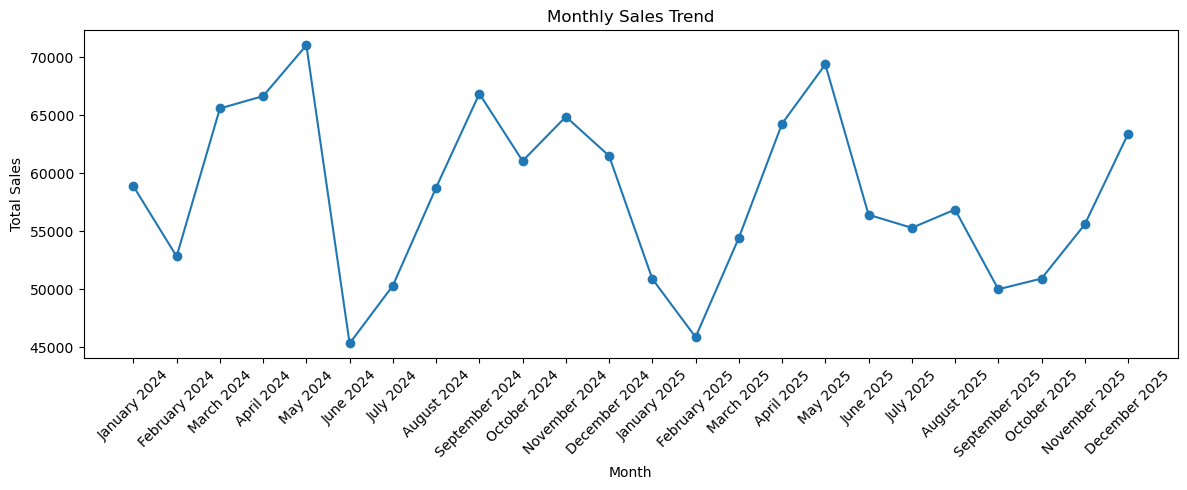

In [104]:
monthly_sales = data.groupby(["Order Year", "Order Month Num", "Order Month"])["Sales"].sum().reset_index()
monthly_sales = monthly_sales.sort_values(["Order Year", "Order Month Num"])

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Order Month"] + " " + monthly_sales["Order Year"].astype(str), monthly_sales["Sales"], marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [105]:
top_products = data.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(10)
print(top_products)

bottom_products = data.groupby("Product")["Profit"].sum().sort_values(ascending=True).head(10)
print(bottom_products)

Product
Standing Desk        348891.29
Office Chair         185609.13
Jacket               115049.85
Bookshelf            113068.93
Dumbbell Set          92865.21
Sneakers              91135.07
Headphones            74371.02
Jeans                 54775.26
Bluetooth Speaker     50911.98
Webcam                43616.63
Name: Sales, dtype: float64
Product
Green Tea         1663.900
Olive Oil         1759.375
Coffee Beans      2979.795
Protein Bars      3222.470
Wireless Mouse    3719.060
T-Shirt           4239.490
Running Belt      6404.215
Desk Lamp         6729.430
USB-C Hub         7038.245
Yoga Mat          7983.150
Name: Profit, dtype: float64


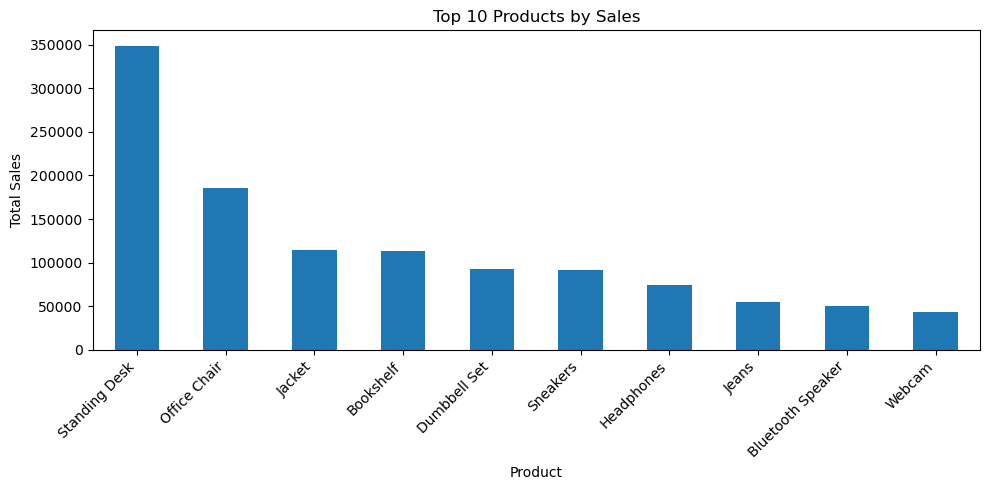

In [106]:
plt.figure(figsize=(10, 5))
top_products.plot(kind="bar")
plt.title("Top 10 Products by Sales")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

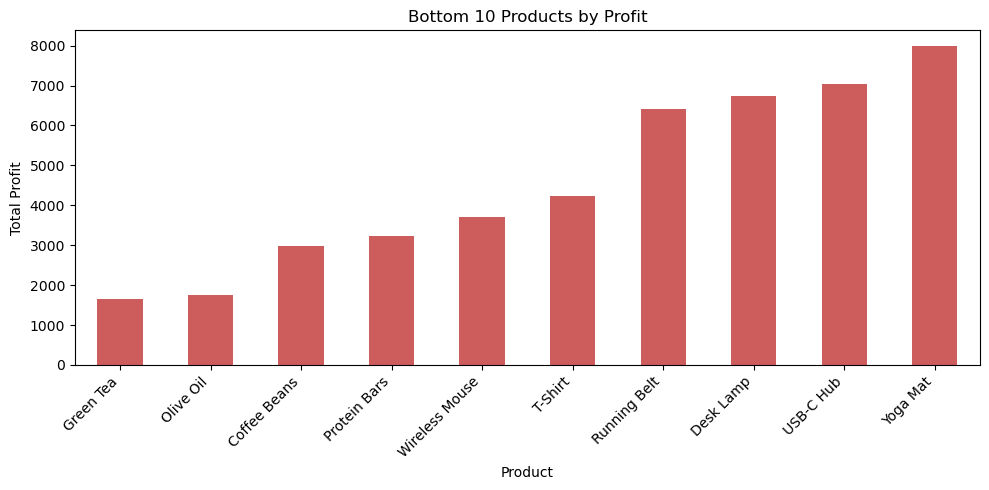

In [107]:
plt.figure(figsize=(10, 5))
bottom_products.plot(kind="bar", color="indianred")
plt.title("Bottom 10 Products by Profit")
plt.ylabel("Total Profit")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

            Sales     Profit
Region                      
South   364782.95  72170.740
West    361793.99  70088.270
East    347589.92  69601.600
North   322829.41  66715.755


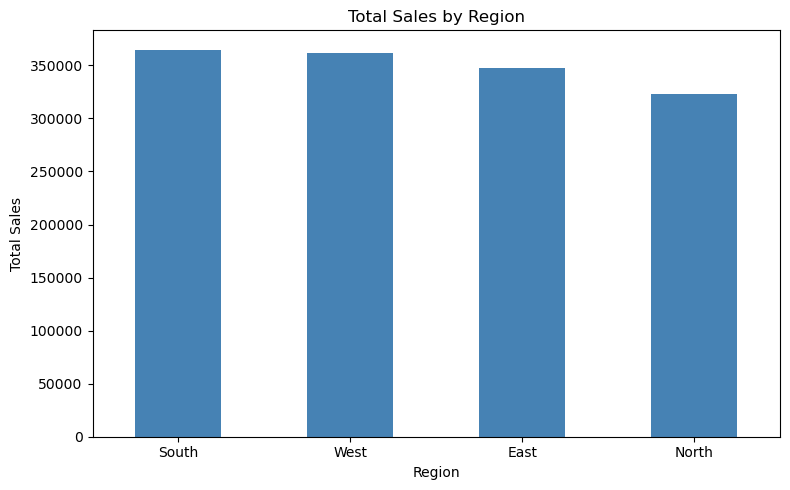

In [114]:
region_summary=data.groupby("Region")[["Sales","Profit"]].sum().sort_values("Sales",ascending=False)
print(region_summary)
region_summary["Sales"].plot(kind="bar", figsize=(8, 5), color="steelblue")
plt.title("Total Sales by Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

                 Sales      Profit
Category                          
Furniture    685085.54  134234.255
Clothing     281485.51   57120.220
Electronics  221571.23   44718.670
Sports       161698.62   32877.680
Groceries     47155.37    9625.540


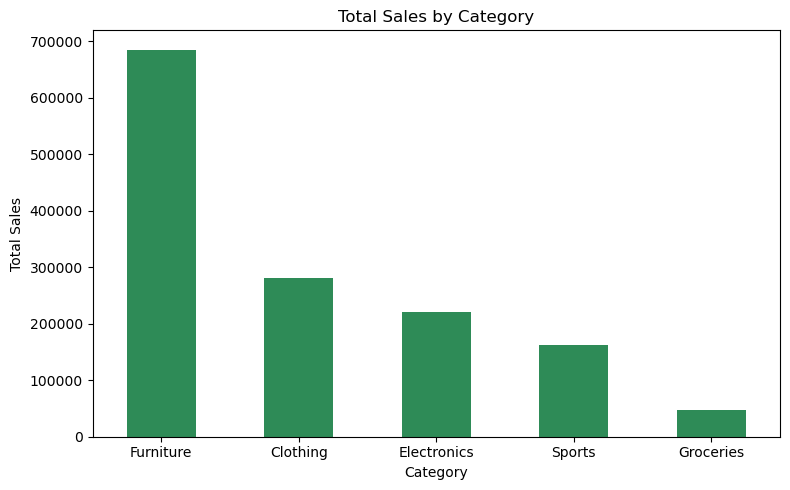

In [115]:
category_summary = data.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
print(category_summary)

category_summary["Sales"].plot(kind="bar", figsize=(8, 5), color="seagreen")
plt.title("Total Sales by Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Discount
0.00    20.30
0.05    20.56
0.10    20.64
0.15    20.37
0.20    20.41
Name: Profit Margin %, dtype: float64


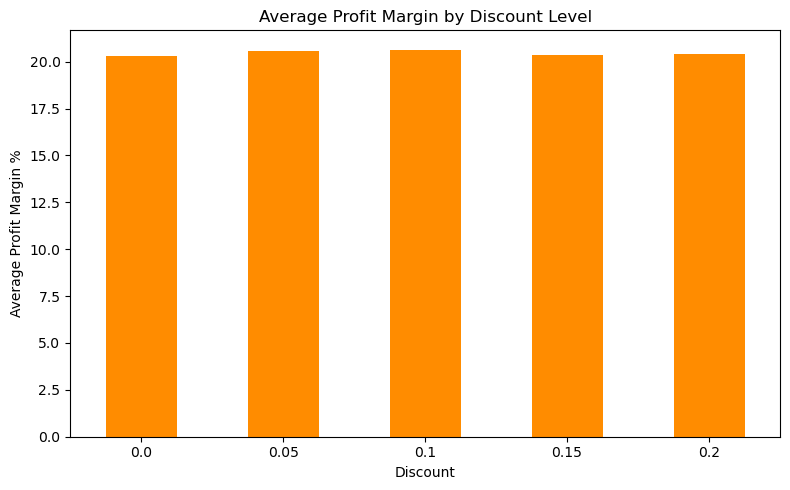

In [116]:
discount_summary = data.groupby("Discount")["Profit Margin %"].mean().round(2)
print(discount_summary)

discount_summary.plot(kind="bar", figsize=(8, 5), color="darkorange")
plt.title("Average Profit Margin by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Average Profit Margin %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Category
Sports         12.47
Clothing       12.40
Electronics    12.22
Furniture      11.90
Groceries      11.55
Name: Returned, dtype: float64


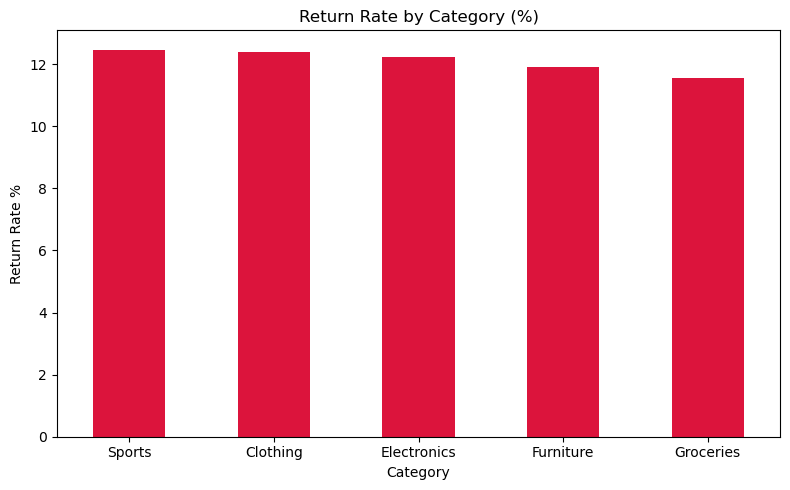

In [117]:
return_rate = data.groupby("Category")["Returned"].apply(lambda x: (x == "Yes").mean() * 100).round(2)
return_rate = return_rate.sort_values(ascending=False)
print(return_rate)

return_rate.plot(kind="bar", figsize=(8, 5), color="crimson")
plt.title("Return Rate by Category (%)")
plt.ylabel("Return Rate %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

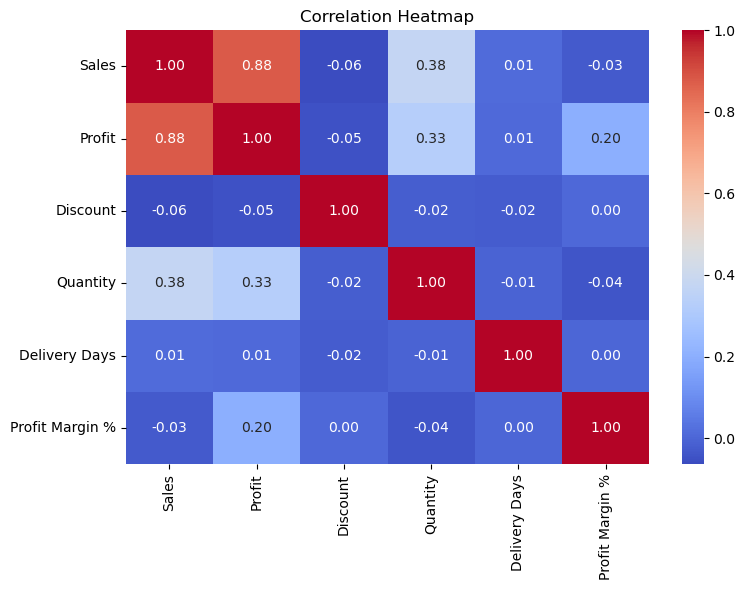

In [118]:
numeric_cols = data[["Sales", "Profit", "Discount", "Quantity", "Delivery Days", "Profit Margin %"]]
correlation = numeric_cols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Total Sales: 1,396,996.27, Total Profit: 278,576.37, Average Order Value: 288.22, 600 unique customers
# Standing Desk is the top product by sales at about 350,000, nearly double the next highest product
# Furniture is the leading category at about 685,000 in sales, more than double Clothing in second place
# Sales are fairly even across regions, from 322,820 (North) to 364,782 (South)
# Discount has almost no effect on profit margin, which stays between 20.30% and 20.64% at every discount level
# Return rates are consistent across categories, ranging narrowly from 11.55% to 12.40%
# Sales and Profit are strongly correlated (0.88), while Discount and Delivery Days show almost no relationship with anything